# PhaseNet y paridad del navegador

**Pregunta:** ¿Cómo varían los puntajes nativos M08 y M13 en estratos reales STEAD, y está verificada la paridad del navegador?
**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Compare puntuaciones nativas de fase M08/M13 en estratos reales de estrés STEAD y separe calidad del benchmark de paridad web no verificada.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

PhaseNet mapea ondas de tres componentes a probabilidades por muestra; máximos y umbrales definen picks. Cite artículo/software primarios y use evidencia retenida propia: 6.000 STEAD reales, 5.926 válidas, 74 rechazadas, referencia de analistas ±0,5 s. Activos de navegador: 24 trazas reales, 100 Hz, 60 s, conteos float32 normalizados. Manifiesto declara paridad falsa y probabilidades no calibradas. Grafique F1 P/S nativo y falsos picks, indicando paridad como gate aparte. Exactitud nativa no prueba ejecución en navegador. Para release se comparan probabilidades y picks en mismas trazas retenidas, preservando negativos y declarando incertidumbre de anotación y cambio de dominio.

PhaseNet mapea formas de onda de tres componentes a probabilidades por muestra; reglas de pico y umbral producen picks. F1 retenido a ±0.5 s y fracción de falsas detecciones en ruido válido responden preguntas distintas. El manifiesto web contiene solo 24 trazas y marca paridad falsa y probabilidades no calibradas; puntuaciones nativas no demuestran inferencia web.

## Comparación

La comparación identifica los algoritmos publicados, el código del producto y la evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

### Picker aprendido y límite de evidencia

PhaseNet es un modelo temporal totalmente convolucional que transforma ventanas de tres componentes en probabilidades por muestra de P, S y ruido. Un detector de picos y umbrales por fase convierten probabilidades en candidatos. STA/LTA forma razones de energía de ventanas corta/larga y cruces de umbral sin clasificar fases. Ambos dependen de orientación, intervalo, normalización y convención de referencia. Un canal ausente o respuesta instrumental distinta es cambio de dominio, no solo diferencia gráfica.

El benchmark retenido agrupa eventos y estaciones para reducir fuga entre trazas correlacionadas. Reporta rendimiento dentro de tolerancia temporal declarada; según protocolo, conserva rechazos QC como no picks en denominador. F1 combina precisión y recall, pero puede ocultar falsos disparos en ruido válido, por eso se reporta fracción falsa aparte. Estratos de componentes perdidos, ruido y desplazamiento prueban estreses declarados, no todos los instrumentos, regiones tectónicas o prácticas de anotación.

El manifiesto del navegador contiene solo 24 trazas y marca paridad falsa y probabilidades no calibradas. Puntajes nativos no prueban pesos, normalización, mapeo de canales, layout, lógica de picos ni precisión idénticos en navegador. Paridad exige comparar salidas por muestra y picks finales en trazas fijas con tolerancias. Hasta pasar esa puerta, navegador es inspección, no servicio PhaseNet validado.

Las llamadas STA/LTA son análisis ejecutable sobre trazas reales derivadas de STEAD. El candidato P temprano muestra que una traza no resume calidad poblacional. M08/M13 usa trazas retenidas y conserva omisiones y falsos picks en ruido. Etiquetas analistas son referencias, no verdad geológica; tolerancia y anotación acotan interpretación. No se entrena modelo nuevo ni se implica calibración no verificada.

## Resultados

**Respuesta:** La selección STEAD real tiene 6.000 trazas (5.926 válidas, 74 rechazadas por QC). Paridad web y calibración son falsas; la traza da P=1.19 s y S=7.02 s frente a referencias 7.00 s y 12.77 s.

## Resumen

Las puntuaciones nativas describen solo el benchmark STEAD. La paridad web sigue sin verificarse hasta comparar probabilidades y picks en trazas idénticas; las llegadas analistas tienen incertidumbre y no son verdad geológica.

## Referencias

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)


### Diagnóstico 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
# Inspeccione el benchmark real retenido y las condiciones de los recursos del navegador.
import json
from pathlib import Path

b = json.loads((root / "data/derived/phase/stead-heldout-benchmark.json").read_text(encoding="utf-8"))
m = json.loads((root / "data/derived/phase/browser-assets/stead/manifest.json").read_text(encoding="utf-8"))
print("seleccionadas/válidas/rechazadas", b["selected"], b["valid"], b["qc_rejected"], "referencia", b['reference'])


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
seleccionadas/válidas/rechazadas 6000 5926 74 referencia STEAD manual P/S picks, not geological truth


### El manifiesto del benchmark identifica las trazas seleccionadas para el navegador, la forma de entrada de tres componentes, la frecuencia de muestreo y los metadatos de calibración. Informe la paridad y la calibración de probabilidades como campos separados: una puntuación del entorno nativo no demuestra que el navegador use los mismos pesos, preprocesamiento o convenciones de salida.

In [2]:
# Separe puntuaciones nativas y paridad web: validan rutas de ejecución distintas.
print(
    "trazas del navegador",
    m["selection"]["selected"],
    "forma",
    m["input"]['shape'],
    "Hz",
    m["input"]["sample_rate_hz"],
    "paridad",
    m["browser_parity_verified"],
    "calibrado",
    m['model']["probabilities_calibrated"],
)


trazas del navegador 24 forma [1, 3, 6000] Hz 100 paridad False calibrado False


### Diagnóstico 2

Calcule la comparación y grafíquela con unidades físicas.

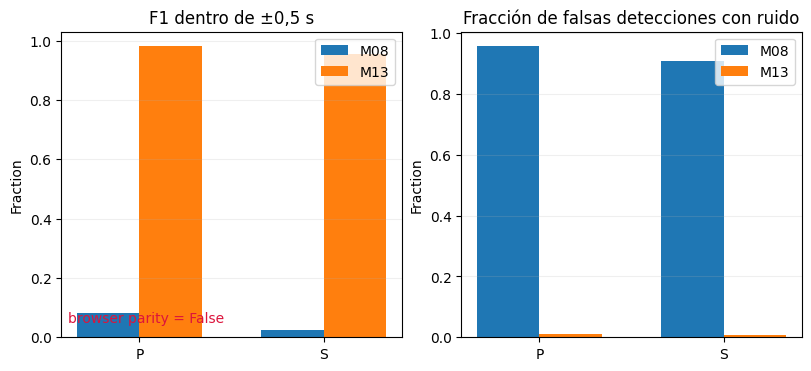

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Compare F1 retenido y tasa de falsas detecciones con ruido en el entorno nativo; la paridad sigue siendo una condición independiente.
import matplotlib.pyplot as plt

e = b["metrics"]["nominal"]
phase = ["P", "S"]
x = np.arange(2)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6), constrained_layout=True)
for a, key, title in zip(
    ax, ["f1_at_0p5s", "valid_noise_false_pick_rate"], ["F1 dentro de ±0,5 s", "Fracción de falsas detecciones con ruido"]
):
    for i, name in enumerate(("M08", "M13")):
        a.bar(x + i * 0.34, [e[name][p][key] for p in phase], 0.34, label=name)
    a.set(xticks=x + 0.17, xticklabels=phase, ylabel="Fraction", title=title)
    a.legend()
    a.grid(axis="y", alpha=0.2)
ax[0].text(
    0.02,
    0.05,
    "browser parity = " + str(m["browser_parity_verified"]),
    transform=ax[0].transAxes,
    color="crimson",
)
plt.show()


### El benchmark nativo guardado contiene resultados pareados M08/M13 por estrato de estrés. La paridad del navegador es una propiedad distinta de la publicación; manténgala en falso hasta ejecutar la implementación del navegador sobre las mismas trazas y comparar los resultados numéricamente. Esta celda separa la evidencia de calidad del modelo de la evidencia de equivalencia del despliegue.

In [4]:
# Separe puntuaciones nativas y paridad web: validan rutas de ejecución distintas.
print("La puntuación nativa no establece paridad del navegador.")


La puntuación nativa no establece paridad del navegador.


### Experimento: estratos de estrés retenidos con entradas pareadas y límite de paridad

El benchmark registra M08 y M13 sobre las mismas trazas fuente en estratos nominales, pérdida de componentes, mayor ruido y desplazamiento temporal. Represente F1 por fase y fracción de falsos picks válidos por ruido para cada estrato. Son resultados del benchmark nativo contra picks de analistas STEAD (no verdad geológica); los casos rechazados por QC cuentan como no picados. El manifiesto del activo ONNX dice explícitamente que la paridad del navegador **no está verificada**, por lo que los puntajes nativos no prueban que el modelo web se ejecute igual. Inspeccione también el contrato real del tensor del navegador (100 Hz, 3 componentes, 6000 muestras, conteos normalizados) y explique por qué normalización, umbral y orden de canales deben coincidir antes de afirmar paridad.

In [5]:
# Prepare coordenadas pareadas por estrato de estrés para la comparación en el entorno nativo.
strata = list(b["metrics"])
phases = ("P", "S")
x = np.arange(len(strata))
width = 0.19


### Comparar resultados del benchmark nativo

Las barras emparejadas informan F1 de M08 y M13 en los mismos estratos de prueba. El segundo panel muestra las fracciones de falsas detecciones de M13 con ruido válido y permite detectar si una mejora de puntuación coincide con un peor comportamiento ante ruido. Son resultados del runtime nativo; la paridad de inferencia en navegador sigue sin verificarse.

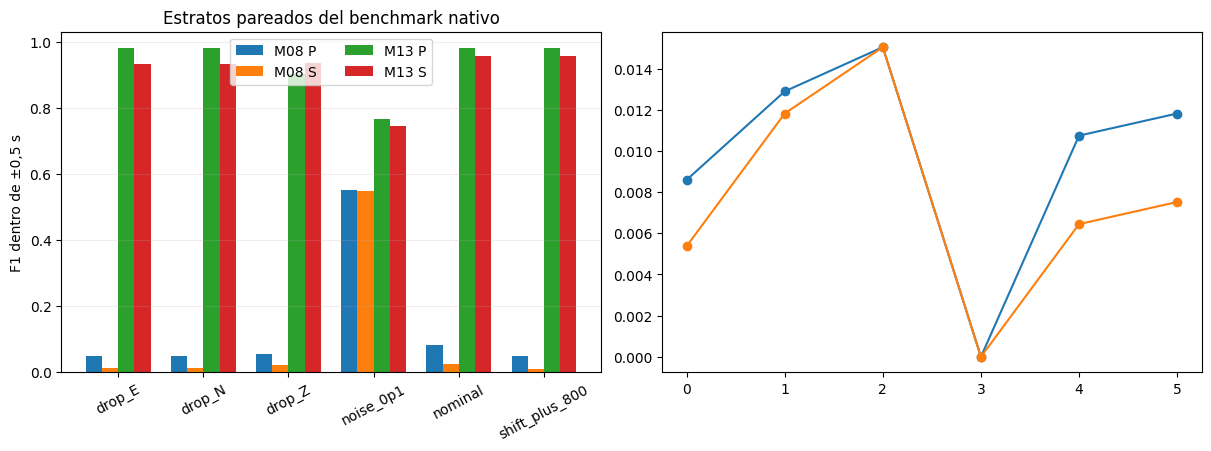

In [6]:
# Compara las dimensiones del modelo y de fase entre grupos de validación estratificados.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
phases = ("P", "S")
x = np.arange(len(strata))
width = 0.19
for j, method in enumerate(("M08", "M13")):
    for k, phase in enumerate(phases):
        vals = [b["metrics"][name][method][phase]["f1_at_0p5s"] for name in strata]
        ax[0].bar(x + (j * 2 + k) * width, vals, width, label=f"{method} {phase}")
        if j == 1:
            nf = [b["metrics"][name][method][phase]["valid_noise_false_pick_rate"] for name in strata]
            ax[1].plot(x, nf, marker="o", label=f"{phase} M13")
ax[0].set(
    xticks=x + 1.5 * width,
    xticklabels=strata,
    ylabel="F1 dentro de ±0,5 s",
    title="Estratos pareados del benchmark nativo",
)
ax[0].tick_params(axis="x", rotation=28)
ax[0].legend(ncol=2)
ax[0].grid(axis="y", alpha=0.2)


### F1 dentro de la tolerancia temporal declarada y la fracción de falsas detecciones con ruido válido responden preguntas distintas. Los paneles pareados muestran si el modelo conserva las detecciones de fase bajo estrés de ruido, mientras que la bandera de paridad marca un límite independiente. Estas puntuaciones proceden del benchmark retenido registrado; no son inferencia recalculada en el navegador ni una afirmación de etiquetas de fase aptas para uso operativo.

In [7]:
# Separe puntuaciones nativas y paridad web: validan rutas de ejecución distintas.
ax[1].set(
    xticks=x,
    xticklabels=strata,
    ylabel="Fracción de falsos picks con ruido válido",
    title="Comportamiento M13 ante ruido",
)
ax[1].tick_params(axis="x", rotation=28)
ax[1].legend()
ax[1].grid(alpha=0.2)
plt.show()
print(
    "Paridad del navegador verificada:",
    m["browser_parity_verified"],
    "; el puntaje nativo no debe presentarse como inferencia del navegador.",
)


Paridad del navegador verificada: False ; el puntaje nativo no debe presentarse como inferencia del navegador.


### Línea base en traza real

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas. Inspeccione los valores impresos antes de cambiar el siguiente control. El resultado es una salida del método con las unidades y limitaciones descritas; no sustituye evaluación retenida ni validación de campo. El resultado sigue condicionado a la entrada sintética o derivada de STEAD declarada y no implica verdad de campo.


In [8]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import sys

sys.path.insert(0, str(root / "data-pipeline"))
from phase_picking import classical_stalta_picks

record_trace = m["records"][0]
raw_trace = (
    np.fromfile(root / "data/derived/phase/browser-assets/stead" / record_trace["waveform_file"], dtype="<f4")
    .reshape(m["input"]['shape'])[0]
    .T
)
raw_vertical = raw_trace[:, 2]
labels = {"P": record_trace["analyst_p_s"], "S": record_trace["analyst_s_s"]}
pars = b["classical_parameters"]
trace_dt = 1.0 / float(m["input"]["sample_rate_hz"])
trace_picks = classical_stalta_picks(raw_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"])
print("Detecciones candidatas STA/LTA", trace_picks)


Detecciones candidatas STA/LTA {'P': 1.19, 'S': 7.0200000000000005}


### Cambio de umbral

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas. Inspeccione los valores impresos antes de cambiar el siguiente control. El resultado es una salida del método con las unidades y limitaciones descritas; no sustituye evaluación retenida ni validación de campo. El resultado sigue condicionado a la entrada sintética o derivada de STEAD declarada y no implica verdad de campo.


In [9]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
trace_picks_high = classical_stalta_picks(
    raw_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"] * 1.25
)
print("Detecciones candidatas con umbral mayor", trace_picks_high)


Detecciones candidatas con umbral mayor {'P': 1.19, 'S': 7.0200000000000005}


### Control previo a llegada

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas. Inspeccione los valores impresos antes de cambiar el siguiente control. El resultado es una salida del método con las unidades y limitaciones descritas; no sustituye evaluación retenida ni validación de campo. El resultado sigue condicionado a la entrada sintética o derivada de STEAD declarada y no implica verdad de campo.


In [10]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
prearrival = raw_trace[: max(32, int(labels["P"] / trace_dt))]
noise_candidates = classical_stalta_picks(
    prearrival, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"]
)
print("Candidatas previas a la llegada", noise_candidates)


Candidatas previas a la llegada {'P': 1.19, 'S': None}


### Control de escala

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas. Inspeccione los valores impresos antes de cambiar el siguiente control. El resultado es una salida del método con las unidades y limitaciones descritas; no sustituye evaluación retenida ni validación de campo. El resultado sigue condicionado a la entrada sintética o derivada de STEAD declarada y no implica verdad de campo.


In [11]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
scaled_trace = raw_trace / max(float(np.std(raw_vertical)), 1e-12)
scaled_candidates = classical_stalta_picks(
    scaled_trace, sample_interval_s=trace_dt, threshold=pars["trigger_ratio"]
)
print("Candidatas en traza normalizada", scaled_candidates)


Candidatas en traza normalizada {'P': 1.19, 'S': 7.0200000000000005}


### Muestras de referencia

Esta celda ejecuta una operación pública del flujo sobre las entradas declaradas. Inspeccione los valores impresos antes de cambiar el siguiente control. El resultado es una salida del método con las unidades y limitaciones descritas; no sustituye evaluación retenida ni validación de campo. El resultado sigue condicionado a la entrada sintética o derivada de STEAD declarada y no implica verdad de campo.


In [12]:
# Ejecute el método nombrado del pipeline con la entrada declarada en la lección.
from pathlib import Path
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
reference_samples = {name: int(round(value / trace_dt)) for name, value in labels.items()}
print("Índices de referencia del analista", reference_samples, "dt (s)", trace_dt)


Índices de referencia del analista {'P': 700, 'S': 1277} dt (s) 0.01


### Evaluar los candidatos ejecutados frente a una traza

El evaluador del repositorio compara cada variante del detector con la misma traza etiquetada por analistas y aplica tolerancia de 0,5 s. La sensibilidad de P y S se informa por separado; una llegada fuera del margen no cuenta como acierto. Una traza verifica el procedimiento, no estima el benchmark.


In [13]:
# Evalúe la misma traza y referencia para cada variante STA/LTA ejecutada.
from phase_picking import evaluate_matched_picks

trace_id = record_trace["trace_id"]
matched = evaluate_matched_picks(
    {trace_id: labels},
    {
        "default": {trace_id: trace_picks},
        "higher_threshold": {trace_id: trace_picks_high},
        "prearrival": {trace_id: noise_candidates},
        "scaled": {trace_id: scaled_candidates},
    },
    tolerance_s=0.5,
)
for method_name, phase_results in matched.items():
    print(method_name, {phase: result["correct_within_tolerance"] for phase, result in phase_results.items()})


default {'P': 0, 'S': 0}
higher_threshold {'P': 0, 'S': 0}
prearrival {'P': 0, 'S': 0}
scaled {'P': 0, 'S': 0}
